# Variational Quantum Eigensolver (VQE): the ground state of a transmon, step by step

This notebook builds a VQE **from scratch** in Qiskit and optimises it with **L-BFGS-B**, a gradient-based
method (we have already covered COBYLA, which is gradient-free). It is written to be read, so every step is
explained and every line of code is commented with the *why*.

## The big picture

VQE finds the lowest energy (the *ground-state energy*) of a Hamiltonian $H$ using a loop between a quantum
circuit and a classical optimiser:

1. A **parameterised circuit** (the *ansatz*) with angles $\vec\theta$ prepares a trial state $|\psi(\vec\theta)\rangle$.
2. An **Estimator** measures the energy $E(\vec\theta) = \langle \psi(\vec\theta) | H | \psi(\vec\theta) \rangle$.
3. A **classical optimiser** (here L-BFGS-B) proposes new angles that lower the energy.
4. Repeat until the energy stops improving.

**Why this works: the variational principle.** For *any* state, $E(\vec\theta) \ge E_0$, where $E_0$ is the true
ground-state energy. So lowering the energy can only move us towards the answer, never past it.
If the circuit is expressive enough to represent the ground state, the minimum of $E(\vec\theta)$ *is* $E_0$.

## The problem we solve

A single transmon (a superconducting qubit) with Hamiltonian

$$H = 4E_C(\hat n - n_g)^2 - E_J\cos\hat\varphi$$

where $E_C$ is the charging energy, $E_J$ the Josephson energy, $\hat n$ the number of excess Cooper pairs on the
island and $n_g$ the offset charge. All energies are in **GHz** (we divide by Planck's constant, so $h = 1$).
The default settings are $E_C = 0.25$ GHz and $E_J/E_C = 40$, the same ratio used in the project plan.

## Contents

| Step | What happens |
|---|---|
| 0 | Imports and settings |
| 1 | Define the Hamiltonian and compute the exact answer classically |
| 2 | Choose the ansatz (the parameterised circuit) |
| 3 | Set up the Estimator (ideal now, noisy later) |
| 4 | Build the cost function and its gradient |
| 5 | Run the classical optimisation loop |
| 6 | Results and convergence plots |
| 7 | Optional: several random starting points |

**Requirements:** `qiskit`, `scipy`, `numpy`, `matplotlib`. `qiskit-aer` is only needed if you switch on the noisy simulator in Step 3.

## Step 0: Imports and settings

Everything you might want to change lives in the settings cell, so you can experiment without hunting through the code.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator   # Qiskit's exact (noiseless) reference Estimator

# ------------------------------------------------------------------
# SETTINGS: change these to explore
# ------------------------------------------------------------------

# --- Physics (energies in GHz, with h = 1) ---
charging_energy_ghz = 0.25            # E_C: cost of adding one Cooper pair to the island
josephson_to_charging_ratio = 40      # E_J / E_C: the key knob (the project plan uses 20, 40 and 60)
offset_charge = 0.0                   # n_g: set to 0 so the charge states are symmetric around n = 0
charge_cutoff = 7                     # N: keep charge states n = -N ... +N (15 states for N = 7)

# --- Ansatz ---
num_ansatz_layers = 4                 # more layers = more expressive circuit, but deeper and harder to run

# --- Optimiser ---
random_seed = 7                       # fixes the random starting angles so results are reproducible
max_iterations = 500                  # safety limit on L-BFGS-B iterations
use_parameter_shift_gradient = True   # True: exact quantum gradient. False: let SciPy estimate it numerically

# --- Execution environment ---
use_noisy_simulator = False           # False: ideal simulator. True: noisy simulator (see Step 3)

# --- Printing ---
print_every_n_iterations = 5          # how often to print a line of the convergence table

## Step 1: Define the Hamiltonian

### 1a. The charge basis

We write the Hamiltonian as a matrix in the **charge basis** $|n\rangle$, where $n = \ldots,-1,0,1,\ldots$ counts
excess Cooper pairs. In this basis:

* The charging term $4E_C(\hat n - n_g)^2$ is **diagonal**: each state $|n\rangle$ has energy $4E_C(n - n_g)^2$.
* The Josephson term $-E_J\cos\hat\varphi$ moves one Cooper pair across the junction, changing $n$ by $\pm 1$.
  Since $\cos\hat\varphi = \tfrac{1}{2}\sum_n \left(|n\rangle\langle n+1| + |n+1\rangle\langle n|\right)$,
  it puts $-E_J/2$ on the two diagonals next to the main one.

### 1b. Charge truncation

The charge $n$ can be any integer, so the true matrix is infinite. We keep only $n = -N,\ldots,N$.
This is a **truncation approximation**. It is accurate if the low-energy states barely occupy charges beyond $\pm N$,
which is true for small $N$ at low $E_J/E_C$ but needs a larger $N$ as $E_J/E_C$ grows. Truncation error is separate
from any error VQE makes, and it is something to keep in mind when you interpret results.

### 1c. Fitting the matrix onto qubits

$q$ qubits describe $2^q$ states, but $2N+1$ is usually not a power of two (15 states needs 4 qubits = 16 states).
We **pad** the matrix with extra states and give them a high energy $E_{\text{pad}}$, so the optimiser has no reason to
put any weight on them. The padding energy must stay **above** the levels we care about (we check this below,
because it will matter when we move to excited states).

In [2]:
# ---- 1a. Build the physical transmon matrix in the charge basis ----

# The charge states we keep: n = -N, ..., +N (integer numbers of Cooper pairs).
charge_values = np.arange(-charge_cutoff, charge_cutoff + 1)
num_charge_states = len(charge_values)

# E_J follows from the ratio. We keep E_C fixed and vary E_J, as in the project plan.
josephson_energy_ghz = josephson_to_charging_ratio * charging_energy_ghz

# Charging term 4 E_C (n - n_g)^2: diagonal, one number per charge state.
charging_term = 4 * charging_energy_ghz * (charge_values - offset_charge) ** 2
physical_H_matrix = np.diag(charging_term)

# Josephson term -E_J cos(phi): couples neighbouring charge states with amplitude -E_J / 2.
tunnelling_amplitude = -josephson_energy_ghz / 2
neighbour_couplings = np.full(num_charge_states - 1, tunnelling_amplitude)
physical_H_matrix = (physical_H_matrix
                     + np.diag(neighbour_couplings, k=+1)    # |n> <-> |n+1>
                     + np.diag(neighbour_couplings, k=-1))   # |n+1> <-> |n>

# ---- 1c. Pad up to a power of two so the matrix fits on whole qubits ----
num_qubits = int(np.ceil(np.log2(num_charge_states)))       # 15 states -> 4 qubits
hilbert_space_dimension = 2 ** num_qubits                    # 4 qubits -> 16 states

# Padding energy: a simple, safe choice is E_J. The lowest levels sit near -E_J, well below it.
padding_energy_ghz = josephson_energy_ghz

H_matrix = padding_energy_ghz * np.eye(hilbert_space_dimension)    # start with padding everywhere...
H_matrix[:num_charge_states, :num_charge_states] = physical_H_matrix  # ...then insert the real physics

# Sanity check: a Hamiltonian must be Hermitian (here: real and symmetric).
assert np.allclose(H_matrix, H_matrix.T), "H must be symmetric"

# ---- The exact classical answer: our benchmark ----
# Exact diagonalisation gives all eigenvalues (sorted lowest first) and eigenvectors (columns).
exact_energies, exact_eigenvectors = np.linalg.eigh(H_matrix)
exact_ground_energy = exact_energies[0]
exact_ground_state = exact_eigenvectors[:, 0]

# Padding must sit above the first three levels, otherwise padded states could pose as physical ones later.
assert padding_energy_ghz > exact_energies[2], "padding energy is too low; increase it"

print(f"E_J / E_C            = {josephson_to_charging_ratio}   (E_J = {josephson_energy_ghz} GHz)")
print(f"Charge states kept   = {num_charge_states}  (n = -{charge_cutoff} ... +{charge_cutoff})")
print(f"Qubits needed        = {num_qubits}  (Hilbert space dimension {hilbert_space_dimension})")
print(f"Exact ground energy  = {exact_ground_energy:.10f} GHz   <-- what VQE should find")
print(f"Next two levels      = {exact_energies[1]:.6f}, {exact_energies[2]:.6f} GHz")

E_J / E_C            = 40   (E_J = 10.0 GHz)
Charge states kept   = 15  (n = -7 ... +7)
Qubits needed        = 4  (Hilbert space dimension 16)
Exact ground energy  = -7.8283475171 GHz   <-- what VQE should find
Next two levels      = -3.622766, 0.288571 GHz


### 1d. From matrix to Pauli operator

A quantum computer cannot measure a matrix directly. It measures products of Pauli operators such as `ZZXI`.
So we rewrite $H$ as a weighted sum of **Pauli strings**,

$$H = \sum_k c_k P_k,$$

and the Estimator measures each $\langle P_k\rangle$ and adds them up with weights $c_k$.
Qiskit's `SparsePauliOp` stores exactly this representation.

In [3]:
# Decompose the dense matrix into a sum of weighted Pauli strings.
# .simplify() merges duplicate terms and drops any with (numerically) zero weight.
H_pauli = SparsePauliOp.from_operator(H_matrix).simplify()

print(f"H is a sum of {len(H_pauli)} Pauli strings. The first few:")
print(H_pauli[:4])

H is a sum of 38 Pauli strings. The first few:
SparsePauliOp(['IIII', 'IIIX', 'IIIZ', 'IIXX'],
              coeffs=[18.125+0.j, -4.375+0.j,  2.875+0.j, -2.5  +0.j])


## Step 2: Choose the ansatz

The **ansatz** is the parameterised circuit that prepares our trial state. Choosing it is a balancing act:
too simple and it cannot represent the ground state (VQE converges to the wrong energy, however good the optimiser is);
too deep and it costs more to run and its energy landscape can be harder to optimise.

We use a standard **hardware-efficient ansatz**, built from repeating layers of two ingredients:

* **$R_y(\theta)$ rotations on every qubit.** Our Hamiltonian is real and symmetric, so its ground state can be chosen with real amplitudes.
  $R_y$ gates only produce real amplitudes, so they are all we need (no complex phases).
* **A ring of CNOT gates.** These *entangle* the qubits. Without them every qubit would be independent and the circuit could only prepare simple product states.

One extra layer of $R_y$ gates at the end gives the last CNOTs something to act on.
With $q$ qubits and $L$ layers this uses $q(L+1)$ parameters.

*Rule of thumb:* a real state on 4 qubits has about 15 independent numbers (16 amplitudes, minus normalisation).
With 4 layers we have 20 parameters, more than that, so this circuit has the freedom to reach the ground state in principle.
Whether the *optimiser* actually finds it is a separate question, and that is what this notebook explores.

In [4]:
def build_hardware_efficient_ansatz(number_of_qubits, number_of_layers):
    # Build a parameterised circuit of [RY layer, CNOT ring] repeated, plus a final RY layer.
    # Returns the circuit. Its angles are free parameters named theta[0], theta[1], ...

    total_parameters = number_of_qubits * (number_of_layers + 1)
    angles = ParameterVector("theta", total_parameters)   # symbolic angles, filled in later by the optimiser
    circuit = QuantumCircuit(number_of_qubits)
    next_parameter_index = 0

    for _ in range(number_of_layers):
        # RY layer: one independent rotation per qubit.
        for qubit_index in range(number_of_qubits):
            circuit.ry(angles[next_parameter_index], qubit_index)
            next_parameter_index += 1

        # Entangling ring: qubit 0 -> 1 -> 2 -> ... -> last -> back to 0.
        for qubit_index in range(number_of_qubits):
            circuit.cx(qubit_index, (qubit_index + 1) % number_of_qubits)

    # Final RY layer, so the last CNOTs are followed by tunable rotations.
    for qubit_index in range(number_of_qubits):
        circuit.ry(angles[next_parameter_index], qubit_index)
        next_parameter_index += 1

    return circuit


ansatz_circuit = build_hardware_efficient_ansatz(num_qubits, num_ansatz_layers)
num_parameters = ansatz_circuit.num_parameters

print(f"Ansatz: {num_qubits} qubits, {num_ansatz_layers} layers, {num_parameters} free parameters")
print(f"Gate counts: {dict(ansatz_circuit.count_ops())},  depth = {ansatz_circuit.depth()}")
print()
print("A single layer, so you can see the structure (RY rotations, then the CNOT ring, then final RYs):")
print(build_hardware_efficient_ansatz(num_qubits, 1).draw("text"))

Ansatz: 4 qubits, 4 layers, 20 free parameters
Gate counts: {'ry': 20, 'cx': 16},  depth = 21

A single layer, so you can see the structure (RY rotations, then the CNOT ring, then final RYs):
     ┌──────────────┐                          ┌───┐┌──────────────┐
q_0: ┤ Ry(theta[0]) ├──■───────────────────────┤ X ├┤ Ry(theta[4]) ├
     ├──────────────┤┌─┴─┐     ┌──────────────┐└─┬─┘└──────────────┘
q_1: ┤ Ry(theta[1]) ├┤ X ├──■──┤ Ry(theta[5]) ├──┼──────────────────
     ├──────────────┤└───┘┌─┴─┐└──────────────┘  │  ┌──────────────┐
q_2: ┤ Ry(theta[2]) ├─────┤ X ├───────■──────────┼──┤ Ry(theta[6]) ├
     ├──────────────┤     └───┘     ┌─┴─┐        │  ├──────────────┤
q_3: ┤ Ry(theta[3]) ├───────────────┤ X ├────────■──┤ Ry(theta[7]) ├
     └──────────────┘               └───┘           └──────────────┘


## Step 3: Set up the Estimator

The **Estimator primitive** is Qiskit's tool for the question "what is $\langle\psi|O|\psi\rangle$?".
You give it a circuit, an observable $O$ and parameter values, and it returns the expectation value.
This is the only place where the quantum computer (or a simulator of it) is used. Everything else is classical.

Calls look like `estimator.run([(circuit, observable, parameter_values)])`. If `parameter_values` has many rows
(one set of angles per row) the Estimator evaluates all of them in a single call, which we will use to compute gradients efficiently.

### Ideal now, noisy later

We use `StatevectorEstimator`, which computes expectation values **exactly** from the simulated statevector.
There are no shots and no noise, so it isolates the behaviour of the *algorithm* itself.

To keep the swap to noise easy, the rest of the notebook never touches the Estimator directly.
It calls one function, `estimate_energies`, which uses three objects defined in this cell:

| Object | Ideal simulator | Noisy simulator / hardware |
|---|---|---|
| `estimator` | `StatevectorEstimator()` | Aer `EstimatorV2` with a noise model, or an IBM Runtime `EstimatorV2` |
| `circuit_to_execute` | the ansatz as built | the ansatz **transpiled** to the backend's gates |
| `observable_to_measure` | `H_pauli` | `H_pauli` re-mapped to the transpiled circuit's qubit layout |

Set `use_noisy_simulator = True` in Step 0 to switch to a noisy simulator (needs `qiskit-aer`).

In [5]:
# Keeps track of how much work we ask the Estimator to do (useful for comparing optimisers later).
estimator_usage = {"estimator_calls": 0, "circuits_evaluated": 0}

if not use_noisy_simulator:
    # ================= IDEAL SIMULATOR (default) =================
    estimator = StatevectorEstimator()
    circuit_to_execute = ansatz_circuit
    observable_to_measure = H_pauli

else:
    # ================= NOISE INJECTION POINT =================
    # To change the noise, edit this block. Nothing else in the notebook needs to change.
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error
    from qiskit_aer.primitives import EstimatorV2 as AerEstimator
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

    # 1) Describe the noise. Here: depolarising errors, with two-qubit gates much noisier than one-qubit gates
    #    (which is realistic for superconducting hardware). The error rates below are illustrative.
    noise_model = NoiseModel()
    noise_model.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["ry", "rz", "sx", "x"])
    noise_model.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["cx"])

    # 2) A simulated device that applies this noise to every gate it runs.
    noisy_backend = AerSimulator(noise_model=noise_model)

    # 3) Real devices only run a fixed gate set on specific qubits. "Transpiling" rewrites our circuit to fit.
    #    The observable must be re-mapped to match any qubit reordering done by the transpiler.
    pass_manager = generate_preset_pass_manager(optimization_level=1, backend=noisy_backend)
    circuit_to_execute = pass_manager.run(ansatz_circuit)
    observable_to_measure = H_pauli.apply_layout(circuit_to_execute.layout)

    # 4) A noisy Estimator is *statistical*: it estimates each expectation from random shots.
    #    default_precision is the target standard error on each energy (smaller = more shots = slower).
    estimator = AerEstimator.from_backend(noisy_backend, options={"default_precision": 0.02})

    # --- To run on real IBM hardware instead (untested sketch; needs an IBM Quantum account) ---
    # from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as RuntimeEstimator
    # service = QiskitRuntimeService()
    # real_backend = service.least_busy(operational=True, simulator=False)   # or pick a named backend
    # pass_manager = generate_preset_pass_manager(optimization_level=1, backend=real_backend)
    # circuit_to_execute = pass_manager.run(ansatz_circuit)
    # observable_to_measure = H_pauli.apply_layout(circuit_to_execute.layout)
    # estimator = RuntimeEstimator(mode=real_backend)


def estimate_energies(parameter_sets):
    # Return the energy <psi(theta)|H|psi(theta)> for each row of angles in parameter_sets.
    # Accepts a single set of angles (1-D array) or many (2-D array, one set per row).

    parameter_sets = np.atleast_2d(parameter_sets)        # make a single set look like a batch of one
    estimator_usage["estimator_calls"] += 1
    estimator_usage["circuits_evaluated"] += len(parameter_sets)

    # One "pub" (primitive unified bloc): circuit, observable, and the parameter values to bind.
    job = estimator.run([(circuit_to_execute, observable_to_measure, parameter_sets)])
    expectation_values = job.result()[0].data.evs       # one energy per row of parameter_sets
    return np.asarray(expectation_values, dtype=float)


mode_name = "NOISY simulator" if use_noisy_simulator else "ideal (noiseless) simulator"
print(f"Estimator ready: {mode_name}")

Estimator ready: ideal (noiseless) simulator


## Step 4: The cost function and its gradient

The **cost function** is the quantity the optimiser minimises: the energy $E(\vec\theta)$.
Evaluating it is one call to `estimate_energies`.

### Why a gradient?

COBYLA only looks at the *value* of the cost. L-BFGS-B also uses the **gradient** $\partial E/\partial\theta_i$, which says
how the energy changes if each angle is nudged. Knowing which way is downhill, and how steeply, usually means far fewer steps.

### The parameter-shift rule

For a gate $R_y(\theta) = e^{-i\theta Y/2}$ that appears **once** in the circuit, the derivative has an exact formula:

$$\frac{\partial E}{\partial \theta_i} = \frac{E(\theta_i + \tfrac{\pi}{2}) - E(\theta_i - \tfrac{\pi}{2})}{2}.$$

It is *exact*, not an approximation: we just evaluate the circuit twice more per parameter, with that one angle shifted.
This matters because it also works on real quantum hardware, where you cannot "peek" at the state.
Every parameter in our ansatz sits in exactly one $R_y$ gate, so the rule applies to all of them.

Cost of a gradient: $2P$ extra circuit evaluations for $P$ parameters. We build all of them as one batch so the Estimator runs them in a single call.

(The alternative, `use_parameter_shift_gradient = False`, lets SciPy estimate the gradient by tiny finite steps.
That is fine in the ideal simulator but fails badly with noise, since the tiny energy differences get buried in the noise.)

In [6]:
def energy_function(parameters):
    # The cost function: the energy for a single set of angles.
    return float(estimate_energies(parameters)[0])


def energy_and_gradient(parameters):
    # Energy and its exact gradient via the parameter-shift rule, using ONE batched Estimator call.
    #
    # Batch layout (rows of angles):
    #   row 0                = the current angles                -> gives the energy
    #   row 1 + 2*i          = angle i shifted by +pi/2          -> E(theta_i + pi/2)
    #   row 2 + 2*i          = angle i shifted by -pi/2          -> E(theta_i - pi/2)

    shift = np.pi / 2
    num_angles = len(parameters)

    batch_of_angle_sets = np.tile(parameters, (1 + 2 * num_angles, 1))      # copy the current angles into every row
    for parameter_index in range(num_angles):
        batch_of_angle_sets[1 + 2 * parameter_index, parameter_index] += shift
        batch_of_angle_sets[2 + 2 * parameter_index, parameter_index] -= shift

    all_energies = estimate_energies(batch_of_angle_sets)

    energy = all_energies[0]
    energies_shifted_up = all_energies[1::2]        # rows 1, 3, 5, ...
    energies_shifted_down = all_energies[2::2]      # rows 2, 4, 6, ...
    gradient = (energies_shifted_up - energies_shifted_down) / 2
    return float(energy), gradient

### Check the gradient before trusting it

A good habit: compare the parameter-shift gradient against a brute-force numerical derivative
(nudge each angle by a tiny amount and see how the energy changes). They should agree to many decimal places.
We skip this in noisy mode, where tiny nudges are swamped by statistical noise.

In [7]:
if use_noisy_simulator:
    print("Skipping the gradient check: finite differences are meaningless under shot noise.")
else:
    rng_for_check = np.random.default_rng(0)
    test_angles = rng_for_check.uniform(-np.pi, np.pi, num_parameters)

    _, shift_rule_gradient = energy_and_gradient(test_angles)

    tiny_step = 1e-6
    numerical_gradient = np.zeros(num_parameters)
    for parameter_index in range(num_parameters):
        nudge = np.zeros(num_parameters)
        nudge[parameter_index] = tiny_step
        numerical_gradient[parameter_index] = (
            energy_function(test_angles + nudge) - energy_function(test_angles - nudge)
        ) / (2 * tiny_step)

    largest_difference = np.max(np.abs(shift_rule_gradient - numerical_gradient))
    print(f"Largest difference between the two gradients: {largest_difference:.2e}")
    print("Parameter-shift gradient looks correct." if largest_difference < 1e-5
          else "WARNING: the gradients disagree. Check the ansatz.")

Largest difference between the two gradients: 1.32e-08
Parameter-shift gradient looks correct.


## Step 5: The classical optimisation loop

### What is L-BFGS-B?

L-BFGS-B is a **quasi-Newton** method. Plain gradient descent steps straight downhill, which is slow in long, narrow valleys.
Newton's method also uses the *curvature* of the landscape (the second derivatives) to take smarter steps, but computing
those for every parameter is expensive. L-BFGS-B builds a cheap *approximation* of the curvature from the last few gradients
it has seen ("L" is for limited memory), and uses it to choose each step. The "B" means it can also handle bounds on the parameters
(we do not need them here, since angles are periodic).

### Iterations versus evaluations

Each **iteration** is one accepted step. To pick the step length, L-BFGS-B runs a **line search**, which may call the cost function
several times, so there are usually a few more *function evaluations* than iterations. We record both:

* **per evaluation:** every time the optimiser asks for the energy;
* **per iteration:** only the accepted points (this is the clean convergence curve).

### Why the starting point matters

The energy landscape can have local minima, and a gradient method rolls into whichever one is nearest.
We start from random angles with a fixed seed (reproducible). Step 7 repeats the run from several starts.

In [8]:
def run_vqe(initial_parameters):
    # Run L-BFGS-B from the given starting angles. Returns the SciPy result and the energy histories.

    energy_by_evaluation = []        # every energy the optimiser asked for (includes line-search probes)
    energy_by_iteration = []         # energy at each accepted step (the clean convergence curve)
    energy_lookup = {}               # remembers energies we have already computed, keyed by the angles

    def objective_function(parameters):
        # What SciPy minimises. Returns (energy, gradient) when jac=True, or just the energy otherwise.
        if use_parameter_shift_gradient:
            energy, gradient = energy_and_gradient(parameters)
        else:
            energy, gradient = energy_function(parameters), None

        energy_by_evaluation.append(energy)
        energy_lookup[parameters.tobytes()] = energy        # store it so the callback need not recompute it
        return (energy, gradient) if use_parameter_shift_gradient else energy

    def record_iteration(current_parameters):
        # SciPy calls this after every accepted iteration.
        known_energy = energy_lookup.get(current_parameters.tobytes())
        if known_energy is None:                             # fallback: compute it if we did not store it
            known_energy = energy_function(current_parameters)
        energy_by_iteration.append(known_energy)

    # Iteration 0 is the starting point, before any optimisation has happened.
    energy_by_iteration.append(energy_function(initial_parameters))

    optimisation_result = minimize(
        objective_function,
        initial_parameters,
        method="L-BFGS-B",
        jac=use_parameter_shift_gradient,    # True: objective_function also returns the gradient
        callback=record_iteration,
        options={
            "maxiter": max_iterations,
            "ftol": 1e-14,                   # stop when the energy stops improving by this relative amount
            "gtol": 1e-10,                   # ...or when the gradient is essentially zero
        },
    )
    return optimisation_result, energy_by_iteration, energy_by_evaluation


# Random starting angles in [-pi, pi]; the seed makes the run reproducible.
random_number_generator = np.random.default_rng(random_seed)
initial_parameters = random_number_generator.uniform(-np.pi, np.pi, num_parameters)

estimator_usage.update({"estimator_calls": 0, "circuits_evaluated": 0})   # reset the counters for a clean tally
optimisation_result, energy_by_iteration, energy_by_evaluation = run_vqe(initial_parameters)
optimal_parameters = optimisation_result.x

print("Optimisation finished.")
print(f"  Reason for stopping : {optimisation_result.message}")
print(f"  Iterations          : {optimisation_result.nit}")
print(f"  Function evaluations: {optimisation_result.nfev}")
print(f"  Estimator calls     : {estimator_usage['estimator_calls']}  ({estimator_usage['circuits_evaluated']} circuit evaluations in total)")

Optimisation finished.
  Reason for stopping : CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  Iterations          : 224
  Function evaluations: 241
  Estimator calls     : 242  (9882 circuit evaluations in total)


## Step 6: Results and convergence

We compare the VQE answer with the exact classical energy from Step 1. Three things to look at:

1. **The energy error**, converted to MHz (our energies are in GHz, and 1 GHz = 1000 MHz), because the plan's accuracy targets are quoted in MHz.
2. **The convergence curves**: energy per iteration, and the error on a log scale. The log plot shows the final digits of accuracy that a linear plot hides.
3. **The state itself.** The energy can be right only if the state is right (the variational principle again),
   so we also compute the **fidelity** between the VQE state and the exact ground state, and compare their charge distributions.

In [9]:
final_energy = energy_by_iteration[-1]
energy_error_ghz = final_energy - exact_ground_energy       # always >= 0 in ideal mode (variational principle)

print(f"Exact ground energy : {exact_ground_energy:.12f} GHz")
print(f"VQE energy          : {final_energy:.12f} GHz")
print(f"Error               : {energy_error_ghz:.3e} GHz  =  {energy_error_ghz * 1000:.3e} MHz")
print()

# ---- Convergence table (printed every few iterations, and always the last) ----
print(f"{'iteration':>9}  {'energy (GHz)':>16}  {'error (GHz)':>12}")
last_iteration = len(energy_by_iteration) - 1
for iteration_number, energy_at_iteration in enumerate(energy_by_iteration):
    if iteration_number % print_every_n_iterations == 0 or iteration_number == last_iteration:
        error_at_iteration = energy_at_iteration - exact_ground_energy
        print(f"{iteration_number:>9}  {energy_at_iteration:>16.8f}  {error_at_iteration:>12.3e}")

Exact ground energy : -7.828347517112 GHz
VQE energy          : -7.828347517111 GHz
Error               : 2.442e-13 GHz  =  2.442e-10 MHz

iteration      energy (GHz)   error (GHz)
        0       15.49525235     2.332e+01
        5       -3.54965133     4.279e+00
       10       -7.25536938     5.730e-01
       15       -7.79926830     2.908e-02
       20       -7.82099589     7.352e-03
       25       -7.82457019     3.777e-03
       30       -7.82587548     2.472e-03
       35       -7.82684292     1.505e-03
       40       -7.82727379     1.074e-03
       45       -7.82742979     9.177e-04
       50       -7.82746762     8.799e-04
       55       -7.82757850     7.690e-04
       60       -7.82764763     6.999e-04
       65       -7.82769604     6.515e-04
       70       -7.82771900     6.285e-04
       75       -7.82774570     6.018e-04
       80       -7.82777193     5.756e-04
       85       -7.82778301     5.645e-04
       90       -7.82779363     5.539e-04
       95       -7.82

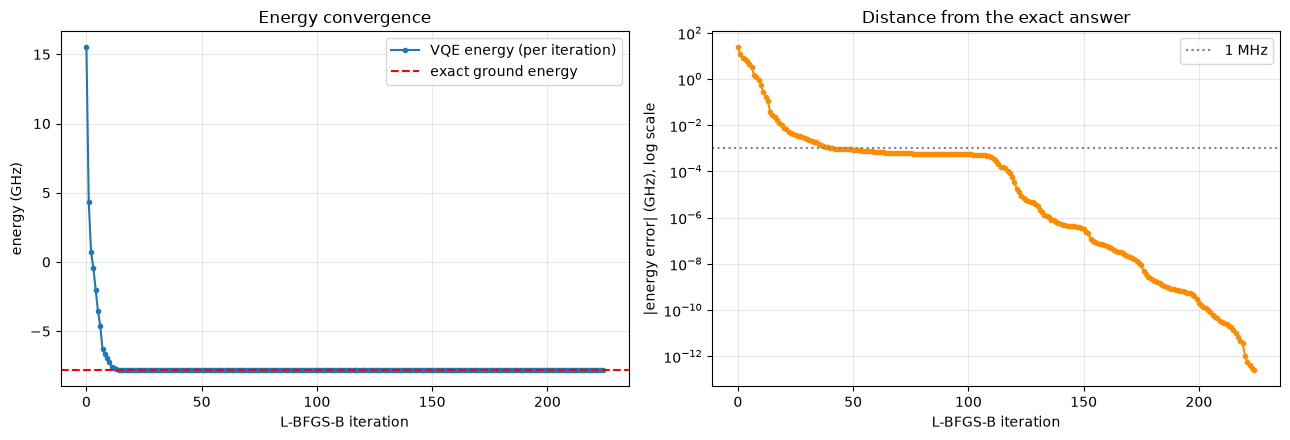

In [10]:
# ---- Convergence plots ----
iteration_numbers = np.arange(len(energy_by_iteration))
errors_by_iteration = np.abs(np.array(energy_by_iteration) - exact_ground_energy)
errors_by_iteration = np.maximum(errors_by_iteration, 1e-16)   # avoid log(0) once we hit machine precision

figure, (energy_axes, error_axes) = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: the energy itself, approaching the exact value from above.
energy_axes.plot(iteration_numbers, energy_by_iteration, "o-", markersize=3, label="VQE energy (per iteration)")
energy_axes.axhline(exact_ground_energy, color="red", linestyle="--", label="exact ground energy")
energy_axes.set_xlabel("L-BFGS-B iteration")
energy_axes.set_ylabel("energy (GHz)")
energy_axes.set_title("Energy convergence")
energy_axes.legend()
energy_axes.grid(alpha=0.3)

# Right: the same data as an error on a log scale. Straight-line decay means steady (exponential) convergence.
error_axes.semilogy(iteration_numbers, errors_by_iteration, "o-", markersize=3, color="darkorange")
error_axes.axhline(1e-3, color="gray", linestyle=":", label="1 MHz")
error_axes.set_xlabel("L-BFGS-B iteration")
error_axes.set_ylabel("|energy error| (GHz), log scale")
error_axes.set_title("Distance from the exact answer")
error_axes.legend()
error_axes.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

Fidelity with the exact ground state: 1.000000000000   (infidelity = 1.80e-14)
Noiseless energy of the optimised angles: -7.828347517111 GHz


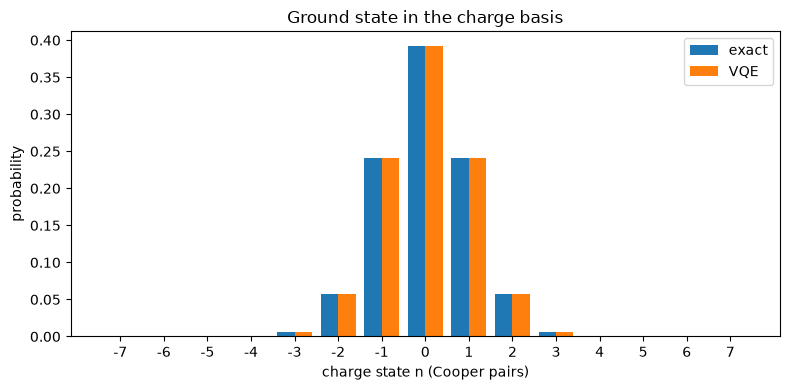

Probability weight the VQE state puts on padded (unphysical) states: 1.24e-15


In [11]:
# ---- Does the VQE state actually match the exact ground state? ----
# We rebuild the ideal statevector for the optimised angles. (Even in noisy mode this shows what the circuit
# with these angles WOULD prepare without noise.)
vqe_state = Statevector(ansatz_circuit.assign_parameters(optimal_parameters)).data

# Fidelity |<exact|VQE>|^2: 1 means identical states. The overall sign/phase of a state is physically meaningless,
# and the absolute value in the formula takes care of that.
state_fidelity = np.abs(np.vdot(exact_ground_state, vqe_state)) ** 2
print(f"Fidelity with the exact ground state: {state_fidelity:.12f}   (infidelity = {1 - state_fidelity:.2e})")

# Energy of these same angles in an ideal (noiseless) world, computed directly from the statevector.
# In ideal mode this equals the final VQE energy. In noisy mode it shows how good the ANGLES are,
# separately from how much the noise distorted the MEASURED energy.
ideal_energy_of_optimal_angles = float(np.real(np.vdot(vqe_state, H_matrix @ vqe_state)))
print(f"Noiseless energy of the optimised angles: {ideal_energy_of_optimal_angles:.12f} GHz")

# Probability of finding the transmon with each charge n (|amplitude|^2). Padded states get n labels too; ignore those.
vqe_probabilities = np.abs(vqe_state) ** 2
exact_probabilities = np.abs(exact_ground_state) ** 2

figure, charge_axes = plt.subplots(figsize=(8, 4))
bar_width = 0.4
charge_positions = np.arange(num_charge_states)
charge_axes.bar(charge_positions - bar_width / 2, exact_probabilities[:num_charge_states], bar_width, label="exact")
charge_axes.bar(charge_positions + bar_width / 2, vqe_probabilities[:num_charge_states], bar_width, label="VQE")
charge_axes.set_xticks(charge_positions)
charge_axes.set_xticklabels(charge_values)
charge_axes.set_xlabel("charge state n (Cooper pairs)")
charge_axes.set_ylabel("probability")
charge_axes.set_title("Ground state in the charge basis")
charge_axes.legend()
plt.tight_layout()
plt.show()

padding_weight = vqe_probabilities[num_charge_states:].sum()
print(f"Probability weight the VQE state puts on padded (unphysical) states: {padding_weight:.2e}")

**Reading the plots**

* The energy approaches the exact value **from above**, never below it. That is the variational principle at work.
  If you ever see the VQE energy drop *below* the exact value in an ideal run, something is wrong (a bug in the Hamiltonian, or in the padding).
* On the log plot, the steep stretches are where the optimiser is making fast progress. Flat stretches mean it is struggling.
* With the default seed our test run showed a long, slow stretch (a *plateau*) before the error suddenly dropped again.
  Plateaus are common in variational algorithms: the gradient is tiny there, so L-BFGS-B takes tiny steps. Your exact curve may differ
  with library versions, and other random starts (Step 7) can avoid or shorten the plateau.
* The probabilities peak at $n = 0$ and spread out to neighbouring charges. That spread is why the charge cutoff $N$ has to be big enough.
  A larger $E_J/E_C$ spreads the state further.

## Step 7 (optional): Several random starting points

A single run can be lucky or unlucky. Gradient methods only find a *nearby* minimum, so the standard practice is to repeat
from several random starts and report the **spread**, not just the best run.

start 0: error = 2.043e-13 GHz  (43 iterations, 46 evaluations)
start 1: error = 7.994e-14 GHz  (81 iterations, 87 evaluations)
start 2: error = 3.908e-14 GHz  (52 iterations, 59 evaluations)
start 3: error = 5.773e-14 GHz  (63 iterations, 70 evaluations)
start 4: error = 4.619e-14 GHz  (71 iterations, 78 evaluations)


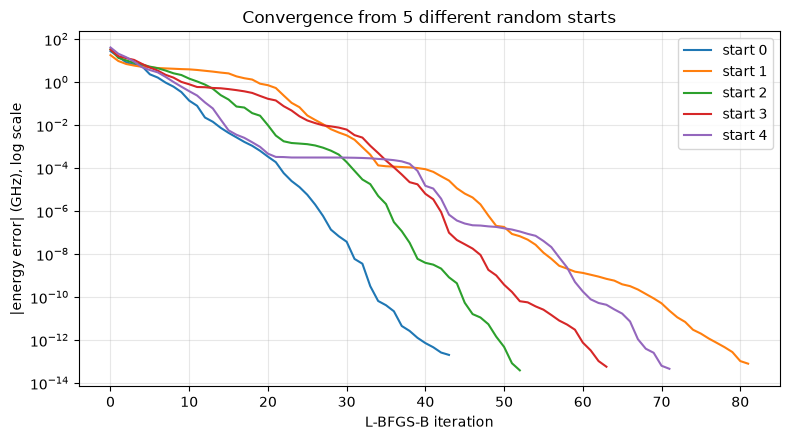

In [12]:
number_of_starts = 5
final_errors_ghz = []
iteration_histories = []

for start_seed in range(number_of_starts):
    starting_angles = np.random.default_rng(start_seed).uniform(-np.pi, np.pi, num_parameters)
    result_for_start, history_for_start, _ = run_vqe(starting_angles)
    final_errors_ghz.append(history_for_start[-1] - exact_ground_energy)
    iteration_histories.append(history_for_start)
    print(f"start {start_seed}: error = {final_errors_ghz[-1]:.3e} GHz  "
          f"({result_for_start.nit} iterations, {result_for_start.nfev} evaluations)")

figure, spread_axes = plt.subplots(figsize=(8, 4.5))
for start_seed, history_for_start in enumerate(iteration_histories):
    history_errors = np.maximum(np.abs(np.array(history_for_start) - exact_ground_energy), 1e-16)
    spread_axes.semilogy(history_errors, label=f"start {start_seed}")
spread_axes.set_xlabel("L-BFGS-B iteration")
spread_axes.set_ylabel("|energy error| (GHz), log scale")
spread_axes.set_title(f"Convergence from {number_of_starts} different random starts")
spread_axes.legend()
spread_axes.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## Things to try (and questions to discuss with the team)

1. **Change the ratio.** Set `josephson_to_charging_ratio` to 20 and 60 and re-run from the top. Does the optimiser behave differently?
   Remember that higher ratios need a larger `charge_cutoff` for the *exact* answer to be converged.
2. **Change the depth.** Try `num_ansatz_layers` = 1, 2, 3. At what point does the error stop being limited by the circuit?
   (If the error plateaus well above zero, the ansatz cannot represent the ground state. That is not an optimiser failure.)
3. **Compare optimisers.** Replace `"L-BFGS-B"` with `"SLSQP"`, or compare against the COBYLA results from earlier.
   Count evaluations as well as accuracy. Note that one parameter-shift gradient costs $2P+1$ circuit evaluations.
4. **Turn the gradient off.** Set `use_parameter_shift_gradient = False`. Does SciPy's numerical gradient change the result or the cost?
5. **Go noisy.** Set `use_noisy_simulator = True` and re-run. Expect the measured energy to stay far above the exact one,
   and the optimiser to stop early. Two separate effects are at work, and it is worth telling them apart:
   (a) noise *biases* the measured energy upward, so even perfect angles would not reach the exact value;
   (b) a statistical Estimator makes the energy a jagged function of the angles, so line searches and gradients become unreliable
   and L-BFGS-B may declare convergence too soon. Compare the measured energy with the *noiseless* energy of the same angles (printed in Step 6):
   the gap between those two is the effect of noise on the measurement, and the gap between the noiseless energy and the exact energy
   is the effect on the optimisation. Gradient-free or noise-aware optimisers such as SPSA are designed for this situation.
6. **Truncation.** Lower `charge_cutoff` and watch what happens to the *exact* energies in Step 1, not just to VQE.

## Where this leads

Once the ground state is reliable, VQD (variational quantum deflation) finds excited states by adding a penalty term to the cost function
that punishes overlap with the states already found. The Estimator, ansatz and optimiser from this notebook stay the same,
and only the cost function in Step 4 changes.

## Final check: does the VQE match the ground state?

One last plot that answers the headline question directly. It is styled after the COBYLA plots from Kira's and Datrim's notebooks
so the three implementations can be compared side by side: Kira's version plots energy per optimiser iteration (left panel),
and Datrim's plots energy per cost-function evaluation (right panel). Both show the exact ground-state energy as a dashed line.

If the VQE has matched the ground state, the curve should settle onto the dashed line.

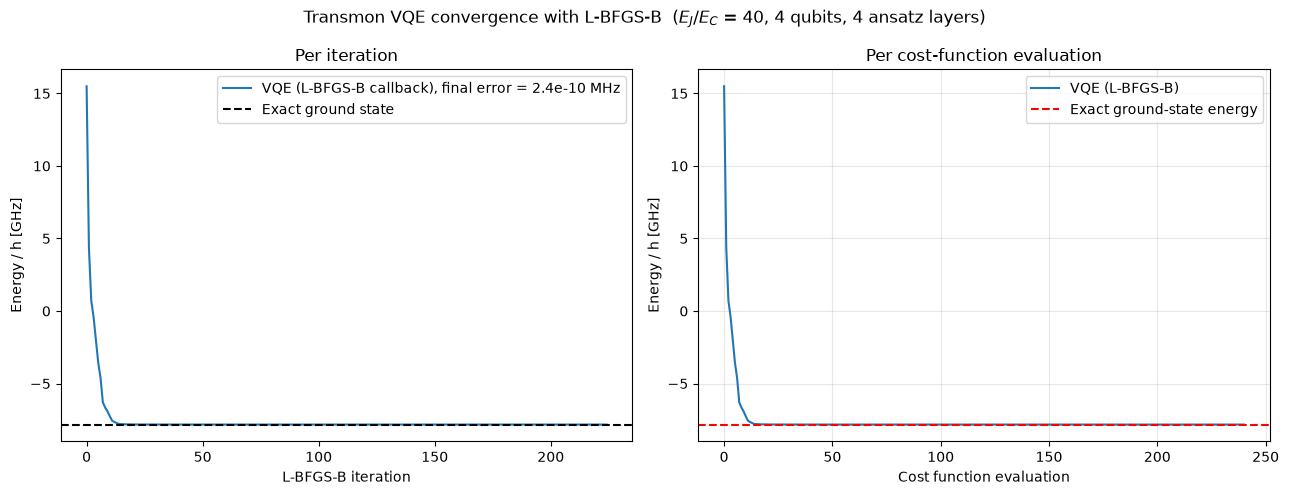

Exact ground energy : -7.8283475171 GHz
VQE final energy    : -7.8283475171 GHz
YES: the VQE matches the exact ground state to 2.4e-10 MHz (target: below 1.0 MHz).


In [13]:
# Final check: does the VQE energy settle onto the exact ground-state energy?

final_vqe_energy = energy_by_iteration[-1]
final_error_mhz = (final_vqe_energy - exact_ground_energy) * 1000     # GHz -> MHz
match_tolerance_mhz = 1.0                                              # the project plan's 1 MHz accuracy target

figure, (iteration_axes, evaluation_axes) = plt.subplots(1, 2, figsize=(13, 5))

# ---- Left panel: energy at each ACCEPTED L-BFGS-B iteration ----
iteration_axes.plot(
    np.arange(len(energy_by_iteration)),
    energy_by_iteration,
    label=f"VQE (L-BFGS-B callback), final error = {final_error_mhz:.1e} MHz",
)
iteration_axes.axhline(exact_ground_energy, color="black", linestyle="--", label="Exact ground state")
iteration_axes.set_xlabel("L-BFGS-B iteration")
iteration_axes.set_ylabel("Energy / h [GHz]")
iteration_axes.set_title("Per iteration")
iteration_axes.legend()

# ---- Right panel: energy at EVERY cost-function evaluation ----
# One evaluation = one request from the optimiser (the line search can request several per iteration).
# With the parameter-shift gradient, each request also costs 2P extra circuit runs, batched into one Estimator call.
evaluation_axes.plot(
    np.arange(len(energy_by_evaluation)),
    energy_by_evaluation,
    label="VQE (L-BFGS-B)",
)
evaluation_axes.axhline(exact_ground_energy, linestyle="--", color="red", label="Exact ground-state energy")
evaluation_axes.set_xlabel("Cost function evaluation")
evaluation_axes.set_ylabel("Energy / h [GHz]")
evaluation_axes.set_title("Per cost-function evaluation")
evaluation_axes.legend()
evaluation_axes.grid(alpha=0.3)

figure.suptitle(
    f"Transmon VQE convergence with L-BFGS-B  ($E_J/E_C$ = {josephson_to_charging_ratio}, "
    f"{num_qubits} qubits, {num_ansatz_layers} ansatz layers)"
)
figure.tight_layout()
plt.show()

# ---- The verdict, in words ----
print(f"Exact ground energy : {exact_ground_energy:.10f} GHz")
print(f"VQE final energy    : {final_vqe_energy:.10f} GHz")
if abs(final_error_mhz) < match_tolerance_mhz:
    print(f"YES: the VQE matches the exact ground state to {abs(final_error_mhz):.1e} MHz "
          f"(target: below {match_tolerance_mhz} MHz).")
else:
    print(f"NO: the VQE is {abs(final_error_mhz):.2f} MHz away from the exact ground state "
          f"(target: below {match_tolerance_mhz} MHz).")